In [ ]:
#29.Load Fashion MNIST through torchvision, apply a transform that converts images to tensors and normalizes them, 
#then display a grid of samples with their labels.
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
transform=transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.5,), (0.5,))])
train_data = torchvision.datasets.FashionMNIST(root="./data",train=True,download=True,transform=transform)
labels = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat","Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
fig, axes = plt.subplots(3, 4, figsize=(10, 7))
for i, ax in enumerate(axes.flat):
    image, label = train_data[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(labels[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

100%|██████████| 26.4M/26.4M [00:30<00:00, 876kB/s] 
100%|██████████| 29.5k/29.5k [00:00<00:00, 177kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 2.01MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 7.71MB/s]


In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
train_data = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform)
test_data = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64)
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10))
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
for epoch in range(5):
    model.train()
    total_loss = 0
    for images, labels in train_loader:
        predictions = model(images)
        loss = loss_fn(predictions, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(
        f"Epoch {epoch + 1}, "
        f"Loss: {total_loss / len(train_loader):.4f}")
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        predictions = model(images)
        predicted_labels = predictions.argmax(dim=1)
        correct += (predicted_labels == labels).sum().item()
        total += labels.size(0)
accuracy = 100 * correct / total
print(f"Baseline Test Accuracy: {accuracy:.2f}%")

Epoch 1, Loss: 0.5013
Epoch 2, Loss: 0.3803
Epoch 3, Loss: 0.3437
Epoch 4, Loss: 0.3189
Epoch 5, Loss: 0.3000
Baseline Test Accuracy: 87.15%


In [2]:
#31.Train a Random Forest on the same flattened pixels as a second baseline, so you 
#have a comparison that is not a neural network at all.
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
X_train = train_data.data.numpy().reshape(60000, -1)
y_train = train_data.targets.numpy()
X_test = test_data.data.numpy().reshape(10000, -1)
y_test = test_data.targets.numpy()
rf_model = RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_predictions)
print(f"Random Forest Test Accuracy: {rf_accuracy * 100:.2f}%")

Random Forest Test Accuracy: 87.60%


In [4]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64)
model = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
for epoch in range(5):
    model.train()
    total_loss = 0
    for images, labels in train_loader:
        predictions = model(images)
        loss = loss_fn(predictions, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(
        f"Epoch {epoch + 1}/5, "
        f"Loss: {total_loss / len(train_loader):.4f}")
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        predictions = model(images)
        predicted_labels = predictions.argmax(dim=1)
        correct += (predicted_labels == labels).sum().item()
        total += labels.size(0)
cnn_accuracy = 100 * correct / total
print(f"CNN Test Accuracy: {cnn_accuracy:.2f}%")

Epoch 1/5, Loss: 0.4893
Epoch 2/5, Loss: 0.3175
Epoch 3/5, Loss: 0.2717
Epoch 4/5, Loss: 0.2436
Epoch 5/5, Loss: 0.2212
CNN Test Accuracy: 90.39%


          Model  Test Accuracy (%)  Training Time (seconds)
Feed Forward NN              87.32                   192.38
  Random Forest              87.60                    36.88
            CNN              90.81                   329.24

Best Model: CNN
Best Test Accuracy: 90.81%


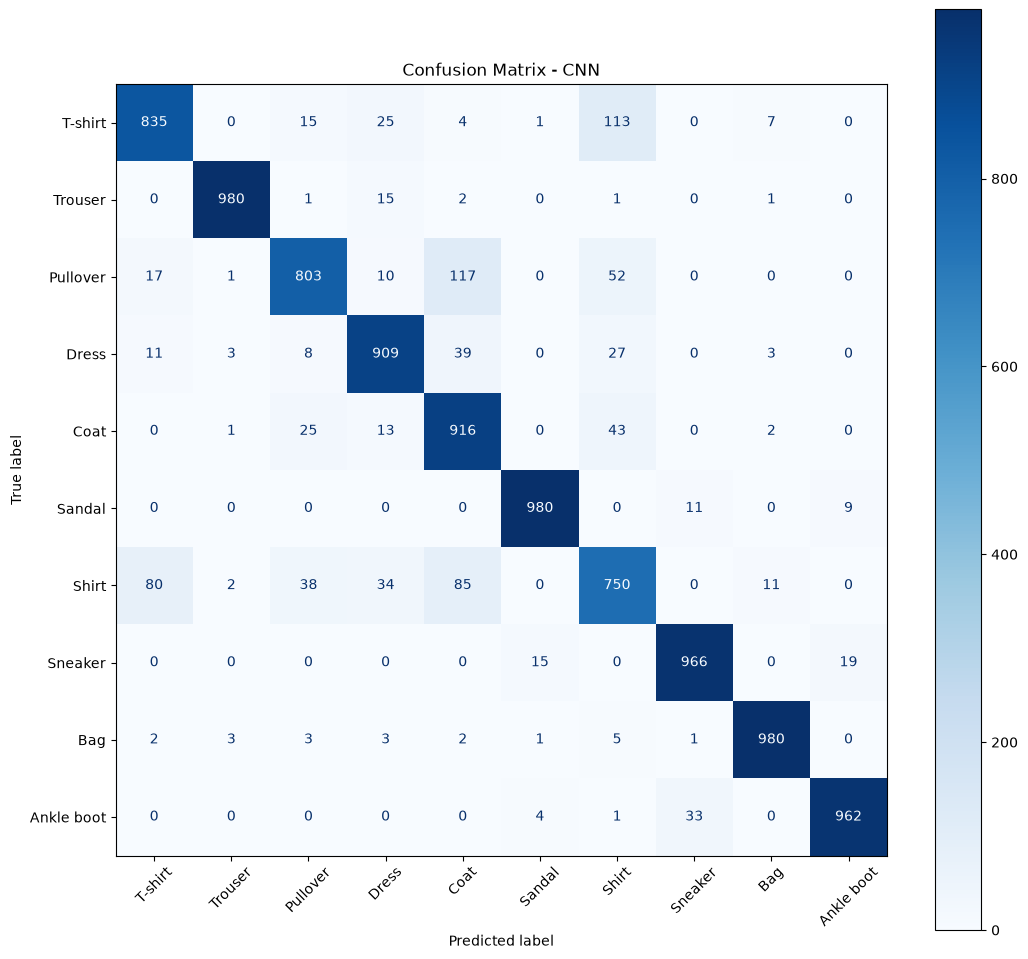

In [7]:
import time
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64)
y_train = train_data.targets.numpy()
y_test = test_data.targets.numpy()
results = {}
ff_model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(ff_model.parameters(), lr=0.001)
start = time.perf_counter()
for epoch in range(5):
    ff_model.train()
    for images, labels in train_loader:
        predictions = ff_model(images)
        loss = loss_fn(predictions, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
ff_time = time.perf_counter() - start
X_train = train_data.data.numpy().reshape(60000, 784)
X_test = test_data.data.numpy().reshape(10000, 784)
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1)
start = time.perf_counter()
rf_model.fit(X_train, y_train)
rf_time = time.perf_counter() - start
cnn_model = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)
start = time.perf_counter()
for epoch in range(5):
    cnn_model.train()
    for images, labels in train_loader:
        predictions = cnn_model(images)
        loss = loss_fn(predictions, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
cnn_time = time.perf_counter() - start
def get_predictions(model, loader):
    model.eval()
    all_predictions = []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images)
            predicted_labels = outputs.argmax(dim=1)
            all_predictions.extend(predicted_labels.numpy())

    return np.array(all_predictions)

ff_predictions = get_predictions(ff_model, test_loader)
cnn_predictions = get_predictions(cnn_model, test_loader)

ff_accuracy = accuracy_score(y_test, ff_predictions) * 100
rf_predictions = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_predictions) * 100
cnn_accuracy = accuracy_score(y_test, cnn_predictions) * 100
results = pd.DataFrame({
    "Model": ["Feed Forward NN", "Random Forest", "CNN"],
    "Test Accuracy (%)": [
        ff_accuracy, rf_accuracy, cnn_accuracy
    ],
    "Training Time (seconds)": [
        ff_time, rf_time, cnn_time]})

print(results.round(2).to_string(index=False))
accuracies = {
    "Feed Forward NN": ff_accuracy,
    "Random Forest": rf_accuracy,
    "CNN": cnn_accuracy}

best_name = max(accuracies, key=accuracies.get)
predictions_dict = {"Feed Forward NN": ff_predictions,"Random Forest": rf_predictions,"CNN": cnn_predictions}
best_predictions = predictions_dict[best_name]
print("\nBest Model:", best_name)
print(f"Best Test Accuracy: {accuracies[best_name]:.2f}%")
class_names = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
cm = confusion_matrix(y_test, best_predictions)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names)
fig, ax = plt.subplots(figsize=(11, 10))
display.plot(ax=ax, xticks_rotation=45, cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()

In [ ]:
import torchvision
import torchvision.transforms as transforms
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))])
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))])
train_data_aug = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=train_transform)
test_data = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=test_transform)
print("Training images:", len(train_data_aug))
print("Testing images:", len(test_data))
from torch.utils.data import DataLoader
import torch
import torch.nn as nn
train_loader_aug = DataLoader(train_data_aug,batch_size=64,shuffle=True)
test_loader = DataLoader(test_data,batch_size=64)

cnn_aug = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cnn_aug.parameters(), lr=0.001)
for epoch in range(5):
    cnn_aug.train()
    total_loss = 0
    for images, labels in train_loader_aug:
        predictions = cnn_aug(images)
        loss = loss_fn(predictions, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {total_loss / len(train_loader_aug):.4f}"
    )
print(f"Original CNN Accuracy: {cnn_accuracy:.2f}%")
print(f"Augmented CNN Accuracy: {aug_accuracy:.2f}%")
print(f"Difference: {aug_accuracy - cnn_accuracy:+.2f}%")